# Courbe d'inflation à 50 ans — Modèle Nelson-Siegel

Ce notebook calibre un modèle de **Nelson-Siegel (NS)** pour construire une courbe d'inflation annuelle sur 50 ans, à partir de 4 inputs utilisateur :

1. **Input 1** : taux d'inflation initial (année 0)
2. **Input 2** : taux d'inflation à long terme (année 50) — la courbe doit y converger
3. **Input 3** : (année, taux cible) — point de calibration intermédiaire n°1
4. **Input 4** : (année, taux cible) — point de calibration intermédiaire n°2

### Modèle

$$y(t) = b_0 + b_1 \cdot \frac{1-e^{-t/\alpha}}{t/\alpha} + b_2 \left(\frac{1-e^{-t/\alpha}}{t/\alpha} - e^{-t/\alpha}\right)$$

- $b_0$ = niveau long terme (input 2)
- $b_1$ = input 1 − input 2 (garantit $y(0)$ = input 1)
- $b_2, \alpha$ = calibrés par optimisation (moindres carrés) sur les points input 3, input 4, et input 2 à l'année 50 (pour forcer la convergence effective à horizon fini).

## 1. Installation / imports

In [ ]:
# Sur Colab, scipy et matplotlib sont déjà installés par défaut.
# Cette ligne ne fait rien si c'est déjà le cas, sinon elle installe ce qu'il faut.
!pip install -q scipy matplotlib numpy pandas

In [ ]:
import numpy as np
from scipy.optimize import least_squares
import matplotlib.pyplot as plt
import pandas as pd
from scipy.interpolate import interp1d
from google.colab import files

## 2. Fonction Nelson-Siegel

In [ ]:
def nelson_siegel(t, b0, b1, b2, alpha):
    """
    Calcule le taux NS pour une ou plusieurs maturités t (en années).
    Gère proprement la limite en t -> 0.
    """
    t = np.asarray(t, dtype=float)
    x = t / alpha

    # f1(t) = (1 - exp(-x)) / x, avec limite f1(0) = 1
    f1 = np.where(x == 0, 1.0, (1 - np.exp(-np.where(x == 0, 1.0, x))) / np.where(x == 0, 1.0, x))
    f2 = f1 - np.exp(-x)

    return b0 + b1 * f1 + b2 * f2

## 3. Calibration de b₂ et α par moindres carrés

In [ ]:
def calibrate_ns(b0, b1, target_points, x0=(0.10, 2.0), bounds=([-1.0, 1.0], [1.0, 50.0])):
    """
    target_points : liste de tuples (maturité_en_années, taux_cible)
                    ex : [(3, 0.03), (21, 0.021), (50, 0.02)]
    x0            : valeurs initiales fictives (b2, alpha)

    NB sur les bornes (bounds) : alpha est contraint à >= 1.0. Sans cette
    contrainte, l'optimiseur peut trouver un alpha très petit (< 0.5) qui
    ajuste un peu mieux les 3 points cibles mais produit une courbe avec
    une légère "bosse" non monotone entre t=0 et le premier point cible
    (la composante de courbure b2 devient alors très locale). La borne
    alpha >= 1.0 donne une courbe économiquement plus réaliste (décroissance
    /convergence lisse) pour un coût quasi nul en qualité d'ajustement
    (écarts < 0.1 pt de % sur les points cibles). Élargissez les bornes si
    vous voulez explicitement autoriser plus de courbure à court terme.
    Retourne (b2_opt, alpha_opt, résultat_optimisation)
    """
    t_arr = np.array([p[0] for p in target_points], dtype=float)
    y_arr = np.array([p[1] for p in target_points], dtype=float)

    def residuals(params):
        b2, alpha = params
        model_vals = nelson_siegel(t_arr, b0, b1, b2, alpha)
        return model_vals - y_arr

    result = least_squares(residuals, x0=list(x0), bounds=bounds)
    b2_opt, alpha_opt = result.x
    return b2_opt, alpha_opt, result

## 4. Construction complète de la courbe à partir des 4 inputs

In [ ]:
def build_inflation_curve(infl_0, infl_50,
                           annee_a, infl_a,
                           annee_b, infl_b,
                           horizon=50,
                           b2_alpha_init=(0.10, 2.0)):
    """
    infl_0   : input 1 - taux d'inflation initial (t=0), ex. 0.04
    infl_50  : input 2 - taux d'inflation long terme (t=50), ex. 0.02
    annee_a, infl_a : input 3 - (année, taux cible), ex. (3, 0.03)
    annee_b, infl_b : input 4 - (année, taux cible), ex. (21, 0.021)
    horizon  : nombre d'années de la courbe (défaut 50)
    """
    # Paramètres fixés par construction
    b0 = infl_50
    b1 = infl_0 - infl_50

    # Points de calibration pour b2 et alpha :
    # les deux points définis par l'utilisateur + le niveau long terme
    # (pour forcer la convergence effective à l'horizon 50 ans)
    target_points = [(annee_a, infl_a), (annee_b, infl_b), (horizon, infl_50)]

    b2, alpha, opt_res = calibrate_ns(b0, b1, target_points, x0=b2_alpha_init)

    # Courbe annuelle sur l'horizon demandé
    years = np.arange(0, horizon + 1)
    curve = nelson_siegel(years, b0, b1, b2, alpha)

    params = {"b0": b0, "b1": b1, "b2": b2, "alpha": alpha}
    return years, curve, params, opt_res, target_points

## 5. -> Inputs utilisateur

👉 Modifiez les 4 valeurs ci-dessous selon votre scénario.

In [ ]:
# ---- INPUTS UTILISATEUR (à modifier) ----
infl_0 = 0.01                 # input 1 : inflation initiale (t=0)
infl_50 = 0.02                # input 2 : inflation long terme (t=50)
annee_a, infl_a = 3, 0.0194     # input 3 : (année, taux cible)
annee_b, infl_b = 21, 0.022   # input 4 : (année, taux cible)
# ------------------------------------------

## 6. Generation Yearly Inflation et vérification

In [ ]:
years, curve, params, opt_res, target_points = build_inflation_curve(
    infl_0, infl_50, annee_a, infl_a, annee_b, infl_b
)

print("Paramètres calibrés du modèle Nelson-Siegel :")
for k, v in params.items():
    print(f"  {k:6s} = {v:.6f}")
print(f"\nConvergence optimisation : {opt_res.success} ({opt_res.message})")

print("\nVérification aux points cibles :")
for t, target in target_points:
    modeled = nelson_siegel(t, **params)
    print(f"  Année {t:>3.0f} : cible = {target:6.3%}  |  modèle = {modeled:6.3%}  "
          f"|  écart = {(modeled - target)*100:+.3f} pts")

Paramètres calibrés du modèle Nelson-Siegel :
  b0     = 0.020000
  b1     = -0.010000
  b2     = 0.021848
  alpha  = 3.028321

Convergence optimisation : True (`gtol` termination condition is satisfied.)

Vérification aux points cibles :
  Année   3 : cible = 1.940%  |  modèle = 1.941%  |  écart = +0.001 pts
  Année  21 : cible = 2.200%  |  modèle = 2.169%  |  écart = -0.031 pts
  Année  50 : cible = 2.000%  |  modèle = 2.072%  |  écart = +0.072 pts


In [ ]:
df = pd.DataFrame({"Année": years, "Inflation": curve})
df["Inflation (%)"] = (df["Inflation"] * 100).round(3)
df[["Année", "Inflation (%)"]]

,Année,Inflation (%)
0,0,1.000
1,1,1.439
2,2,1.738
3,3,1.941
4,4,2.074
5,5,2.161
6,6,2.214
7,7,2.245
8,8,2.261
9,9,2.266


In [ ]:
# Extraction des années et des taux d'inflation annuels
annual_years = df['Année'].values
annual_inflation = df['Inflation'].values

## Intrapolation Monthly

Nous allons créer une fonction d'interpolation à partir de nos données annuelles. L'option `kind='cubic'` spécifie que nous utilisons une interpolation cubique. `fill_value='extrapolate'` permet d'estimer des valeurs en dehors de la plage de données si nécessaire, bien que pour notre cas (de 0 à 50 ans), ce ne soit pas strictement nécessaire si nous restons dans cette plage.

In [ ]:
# Création de la fonction d'interpolation (cubique pour la douceur)
f_interp = interp1d(annual_years, annual_inflation, kind='cubic', fill_value='extrapolate')

Maintenant, nous allons générer une nouvelle série de points pour les mois. Pour 50 ans, cela représente 50 * 12 = 600 mois. Nous utiliserons des valeurs fractionnaires pour les années (ex: 0.0, 1/12, 2/12, ..., 50.0).

In [ ]:
# Génération des points mensuels (en fractions d'années), de t=1/12 (Jan An 1) à t=50 (Dec An 50)
monthly_time_points_for_months = np.arange(1/12, 50 + 1/12, 1/12) # Cela génère 600 points

# Calcul de l'inflation mensuelle interpolée pour ces 600 points
inflation_for_months = f_interp(monthly_time_points_for_months)

# Calcul des colonnes Année et Mois pour ces 600 points
# L'année est le plafond du temps fractionnaire (ex: 0.08 -> An 1, 1.0 -> An 1, 1.08 -> An 2)
annee_col = np.ceil(monthly_time_points_for_months).astype(int)
# Le mois est calculé en fonction de la fraction de l'année en cours
mois_col = np.round((monthly_time_points_for_months - (np.ceil(monthly_time_points_for_months)-1)) * 12).astype(int)

# Création du DataFrame pour les 600 mois
df_monthly_temp = pd.DataFrame({
    'Temps_Fraction_Annee': monthly_time_points_for_months,
    'Annee': annee_col,
    'Mois': mois_col,
    'Inflation': inflation_for_months
})

# Formatage de la colonne Mois_Annee comme 'MM/YY'
df_monthly_temp['Mois_Annee'] = df_monthly_temp.apply(lambda row: f"{int(row['Mois']):02d}/{int(row['Annee']):02d}", axis=1)

# Ajout de la ligne d'inflation initiale (t=0) au début
initial_row = pd.DataFrame({
    'Temps_Fraction_Annee': [0.0],
    'Annee': [np.nan],
    'Mois': [np.nan],
    'Inflation': [infl_0],
    'Mois_Annee': ['Initial']
})

df_monthly = pd.concat([initial_row, df_monthly_temp], ignore_index=True)

df_monthly['Inflation (%)'] = (df_monthly['Inflation'] * 100).round(4)

# Affichage des premières et dernières lignes pour vérification
print("Premières 15 lignes du DataFrame mensuel (601 points incluant 'Initial') :")
display(df_monthly.head(15))
print("\nDernières 5 lignes du DataFrame mensuel :")
display(df_monthly.tail(5))
print(f"\nNombre total de points générés : {len(df_monthly)}")

# --- Vérification des valeurs de Décembre ---
print("\n--- Vérification : Inflation de Décembre (mensuel) vs Inflation Annuelle (df) ---")
verification_results = []
for year in range(1, 51): # Pour les années 1 à 50
    # Inflation mensuelle de Décembre de l'année courante
    dec_inflation_monthly = df_monthly[(df_monthly['Annee'] == year) & (df_monthly['Mois'] == 12)]['Inflation'].iloc[0]

    # Inflation annuelle de l'année courante (du DataFrame original 'df')
    annual_inflation_df = df[df['Année'] == year]['Inflation'].iloc[0]

    # Écart en points de pourcentage
    ecart = (dec_inflation_monthly - annual_inflation_df) * 100
    verification_results.append({
        'Année': year,
        'Dec_Mensuel (%)': dec_inflation_monthly * 100,
        'Annuel_DF (%)': annual_inflation_df * 100,
        'Écart_pts': ecart
    })

df_verification = pd.DataFrame(verification_results)
display(df_verification.head())
display(df_verification.tail())
print(f"\nNombre d'écarts (valeur absolue) > 0.001 pts : {(df_verification['Écart_pts'].abs() > 0.001).sum()} sur 50 années")
print("Si ce nombre est faible, l'interpolation fonctionne bien aux points annuels de Décembre.")

Premières 15 lignes du DataFrame mensuel (601 points incluant 'Initial') :


,Temps_Fraction_Annee,Annee,Mois,Inflation,Mois_Annee,Inflation (%)
0,0.000000,NaN,NaN,0.010000,Initial,1.0000
1,0.083333,1.0,1.0,0.010429,01/01,1.0429
2,0.166667,1.0,2.0,0.010846,02/01,1.0846
3,0.250000,1.0,3.0,0.011251,03/01,1.1251
4,0.333333,1.0,4.0,0.011644,04/01,1.1644
5,0.416667,1.0,5.0,0.012025,05/01,1.2025
6,0.500000,1.0,6.0,0.012395,06/01,1.2395
7,0.583333,1.0,7.0,0.012753,07/01,1.2753
8,0.666667,1.0,8.0,0.013101,08/01,1.3101
9,0.750000,1.0,9.0,0.013438,09/01,1.3438



Dernières 5 lignes du DataFrame mensuel :


,Temps_Fraction_Annee,Annee,Mois,Inflation,Mois_Annee,Inflation (%)
596,49.666667,50.0,8.0,0.020722,08/50,2.0722
597,49.750000,50.0,9.0,0.020721,09/50,2.0721
598,49.833333,50.0,10.0,0.020720,10/50,2.0720
599,49.916667,50.0,11.0,0.020719,11/50,2.0719
600,50.000000,50.0,12.0,0.020718,12/50,2.0718



Nombre total de points générés : 601

--- Vérification : Inflation de Décembre (mensuel) vs Inflation Annuelle (df) ---


,Année,Dec_Mensuel (%),Annuel_DF (%),Écart_pts
0,1,1.438681,1.438681,1.734723e-16
1,2,1.738430,1.738430,-3.469447e-16
2,3,1.940579,1.940579,0.000000e+00
3,4,2.074446,2.074446,0.000000e+00
4,5,2.160790,2.160790,3.469447e-16


,Année,Dec_Mensuel (%),Annuel_DF (%),Écart_pts
45,46,2.077999,2.077999,6.938894e-16
46,47,2.076339,2.076339,3.469447e-16
47,48,2.074749,2.074749,0.000000e+00
48,49,2.073224,2.073224,0.000000e+00
49,50,2.071759,2.071759,0.000000e+00



Nombre d'écarts (valeur absolue) > 0.001 pts : 0 sur 50 années
Si ce nombre est faible, l'interpolation fonctionne bien aux points annuels de Décembre.


Vous pouvez maintenant visualiser cette courbe mensuelle pour voir son aspect plus détaillé.

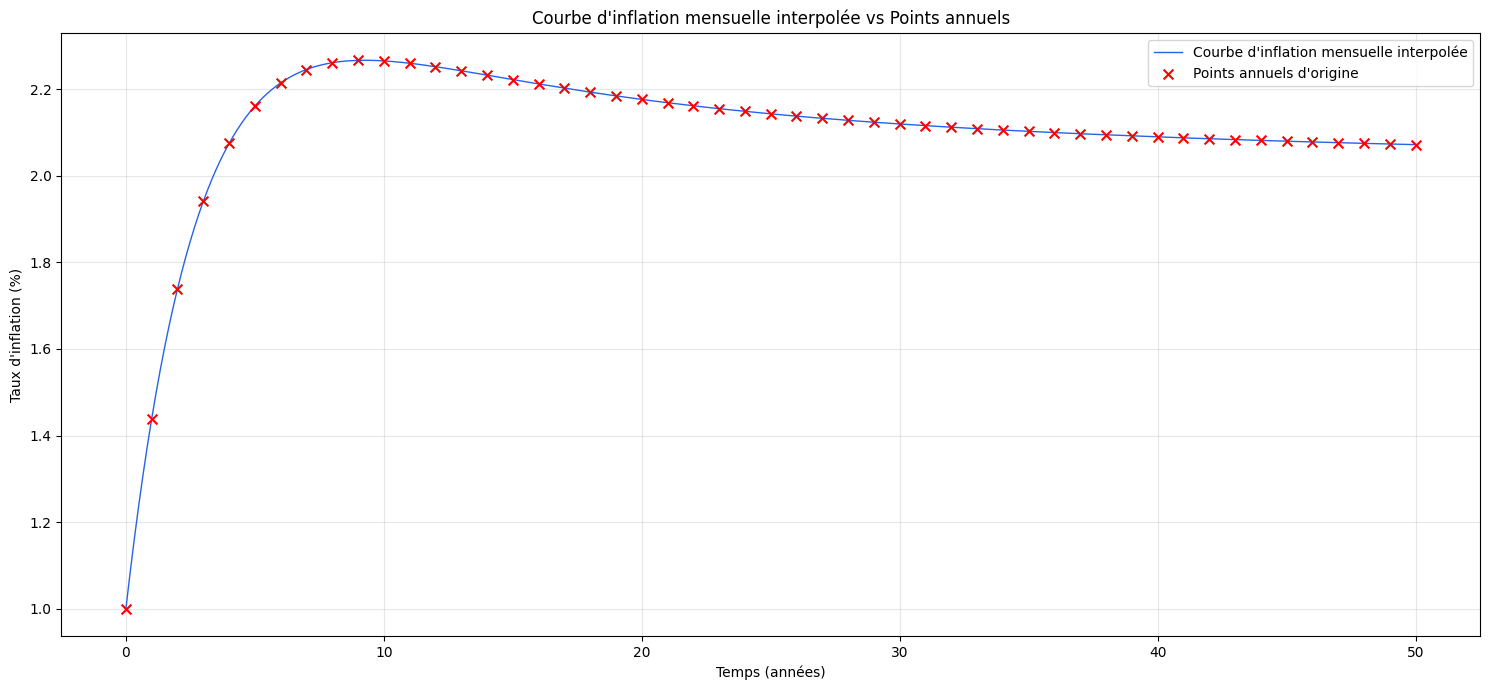

In [ ]:
plt.figure(figsize=(15, 7))
plt.plot(df_monthly['Temps_Fraction_Annee'], df_monthly['Inflation (%)'], label="Courbe d'inflation mensuelle interpolée", color='#2563eb', linewidth=1)
plt.scatter(annual_years, annual_inflation * 100, label="Points annuels d'origine", color='red', marker='x', s=50, zorder=5)

plt.title("Courbe d'inflation mensuelle interpolée vs Points annuels")
plt.xlabel("Temps (années)")
plt.ylabel("Taux d'inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Graphique df Inflation Annuel

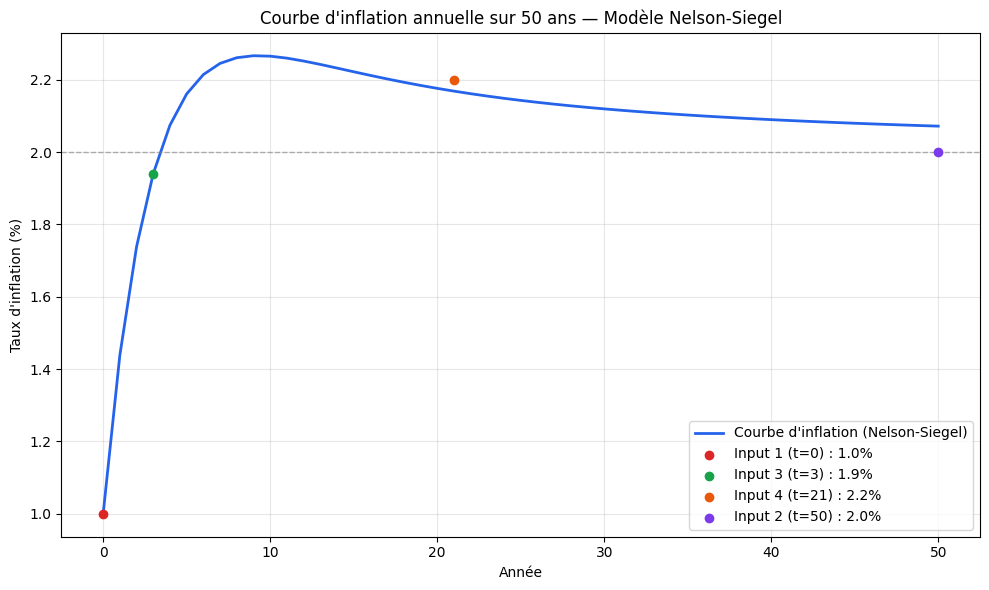

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(years, curve * 100, label="Courbe d'inflation (Nelson-Siegel)", color="#2563eb", linewidth=2)
plt.scatter([0], [infl_0 * 100], color="#dc2626", zorder=5, label=f"Input 1 (t=0) : {infl_0:.1%}")
plt.scatter([annee_a], [infl_a * 100], color="#16a34a", zorder=5, label=f"Input 3 (t={annee_a}) : {infl_a:.1%}")
plt.scatter([annee_b], [infl_b * 100], color="#ea580c", zorder=5, label=f"Input 4 (t={annee_b}) : {infl_b:.1%}")
plt.scatter([50], [infl_50 * 100], color="#7c3aed", zorder=5, label=f"Input 2 (t=50) : {infl_50:.1%}")
plt.axhline(infl_50 * 100, color="gray", linestyle="--", linewidth=1, alpha=0.6)

plt.title("Courbe d'inflation annuelle sur 50 ans — Modèle Nelson-Siegel")
plt.xlabel("Année")
plt.ylabel("Taux d'inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8.Export de la courbe en CSV

Pratique pour réutiliser les résultats ailleurs (Excel, autre modèle, etc.).

In [ ]:
def export_dfs_to_excel(dfs_to_export, excel_file_name="output.xlsx"):
    """
    Exporte plusieurs DataFrames dans un seul fichier Excel, chaque DataFrame étant une feuille distincte.
    Permet ensuite le téléchargement du fichier.

    Args:
        dfs_to_export (dict): Un dictionnaire où les clés sont les noms des feuilles (str)
                              et les valeurs sont les DataFrames (pd.DataFrame) à exporter.
        excel_file_name (str): Le nom du fichier Excel à créer.
    """
    if not isinstance(dfs_to_export, dict) or not all(isinstance(v, pd.DataFrame) for v in dfs_to_export.values()):
        print("Erreur: 'dfs_to_export' doit être un dictionnaire de DataFrames.")
        return

    try:
        with pd.ExcelWriter(excel_file_name, engine="openpyxl") as writer:
            for sheet_name, df_to_write in dfs_to_export.items():
                df_to_write.to_excel(writer, sheet_name=sheet_name, index=False)

        print(f"Fichier créé : {excel_file_name}")

        # Téléchargement
        files.download(excel_file_name)
    except Exception as e:
        print(f"Une erreur est survenue lors de l'exportation ou du téléchargement : {e}")


# Simple NS sans cibles

In [ ]:
def build_inflation_curve_no_targets(infl_0, infl_50, b2_param, alpha_param, horizon=50):
    """
    Construit une courbe d'inflation Nelson-Siegel sans calibration sur des points cibles.
    b2 et alpha sont fournis directement en paramètres.

    infl_0      : taux d'inflation initial (t=0)
    infl_50     : taux d'inflation long terme (t=50)
    b2_param    : paramètre b2 du modèle Nelson-Siegel (courbure)
    alpha_param : paramètre alpha du modèle Nelson-Siegel (taux de décroissance de la courbure)
    horizon     : nombre d'années de la courbe (défaut 50)
    """
    # Paramètres fixés par construction
    b0 = infl_50
    b1 = infl_0 - infl_50

    # Courbe annuelle sur l'horizon demandé
    years = np.arange(0, horizon + 1)
    curve = nelson_siegel(years, b0, b1, b2_param, alpha_param)

    params = {"b0": b0, "b1": b1, "b2": b2_param, "alpha": alpha_param}
    return years, curve, params


--- Modèle Nelson-Siegel sans points cibles ---
Paramètres du modèle Nelson-Siegel (sans cibles) :
  b0     = 0.020000
  b1     = -0.010000
  b2     = 0.000000
  alpha  = 2.000000


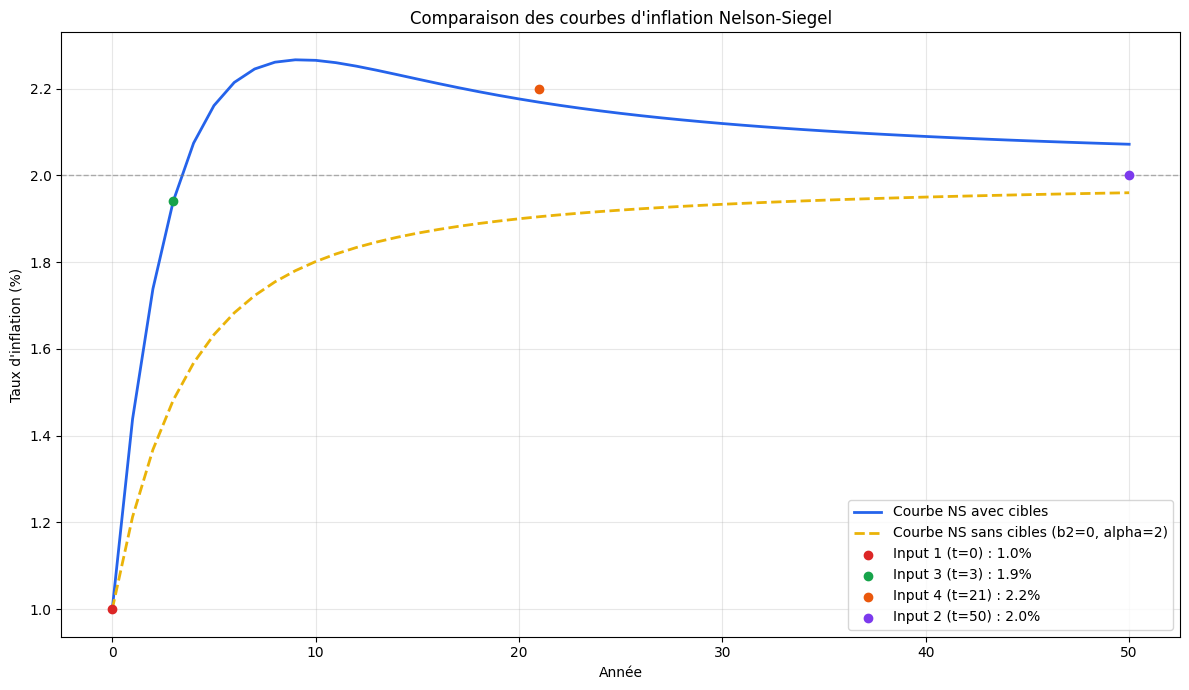

In [ ]:
# --- Utilisation du modèle sans cibles ---
print("\n--- Modèle Nelson-Siegel sans points cibles ---")

# Définir directement b2 et alpha
b2_no_targets = 0.0  # Par exemple, supprimer le terme de courbure
alpha_no_targets = 2.0 # Une valeur typique pour alpha


years_no_targets, curve_no_targets, params_no_targets = build_inflation_curve_no_targets(
    infl_0, infl_50, b2_no_targets, alpha_no_targets
)

print("Paramètres du modèle Nelson-Siegel (sans cibles) :")
for k, v in params_no_targets.items():
    print(f"  {k:6s} = {v:.6f}")

# --- Comparaison des deux courbes ---

# Renommer les variables de la courbe avec cibles pour plus de clarté dans le graphique
years_with_targets = years
curve_with_targets = curve

plt.figure(figsize=(12, 7))
plt.plot(years_with_targets, curve_with_targets * 100, label="Courbe NS avec cibles", color="#2563eb", linewidth=2)
plt.plot(years_no_targets, curve_no_targets * 100, label="Courbe NS sans cibles (b2=0, alpha=2)", color="#eab308", linestyle="--", linewidth=2)

plt.scatter([0], [infl_0 * 100], color="#dc2626", zorder=5, label=f"Input 1 (t=0) : {infl_0:.1%}")
plt.scatter([annee_a], [infl_a * 100], color="#16a34a", zorder=5, label=f"Input 3 (t={annee_a}) : {infl_a:.1%}")
plt.scatter([annee_b], [infl_b * 100], color="#ea580c", zorder=5, label=f"Input 4 (t={annee_b}) : {infl_b:.1%}")
plt.scatter([50], [infl_50 * 100], color="#7c3aed", zorder=5, label=f"Input 2 (t=50) : {infl_50:.1%}")
plt.axhline(infl_50 * 100, color="gray", linestyle="--", linewidth=1, alpha=0.6)

plt.title("Comparaison des courbes d'inflation Nelson-Siegel")
plt.xlabel("Année")
plt.ylabel("Taux d'inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
df_no_targets = pd.DataFrame({"Année": years_no_targets, "Inflation": curve_no_targets})
df_no_targets["Inflation (%)"] = (df["Inflation"] * 100).round(3)
df_no_targets[["Année", "Inflation (%)"]]

,Année,Inflation (%)
0,0,1.000
1,1,1.439
2,2,1.738
3,3,1.941
4,4,2.074
5,5,2.161
6,6,2.214
7,7,2.245
8,8,2.261
9,9,2.266


In [ ]:
# Extraction des années et des taux d'inflation annuels
annual_years_no_targets = df_no_targets['Année'].values
annual_inflation_no_targets = df_no_targets['Inflation'].values

# Intrapolation No Targets

In [ ]:
# Création de la fonction d'interpolation (cubique pour la douceur)
f_interp_no_targets = interp1d(annual_years_no_targets, annual_inflation_no_targets, kind='cubic', fill_value='extrapolate')

# Génération des points mensuels (en fractions d'années), de t=1/12 (Jan An 1) à t=50 (Dec An 50)
monthly_time_points_for_months = np.arange(1/12, 50 + 1/12, 1/12) # Cela génère 600 points

# Calcul de l'inflation mensuelle interpolée pour ces 600 points
inflation_for_months = f_interp_no_targets(monthly_time_points_for_months)

# Calcul des colonnes Année et Mois pour ces 600 points
# L'année est le plafond du temps fractionnaire (ex: 0.08 -> An 1, 1.0 -> An 1, 1.08 -> An 2)
annee_col = np.ceil(monthly_time_points_for_months).astype(int)
# Le mois est calculé en fonction de la fraction de l'année en cours
mois_col = np.round((monthly_time_points_for_months - (np.ceil(monthly_time_points_for_months)-1)) * 12).astype(int)

# Création du DataFrame pour les 600 mois
df_monthly_temp = pd.DataFrame({
    'Temps_Fraction_Annee': monthly_time_points_for_months,
    'Annee': annee_col,
    'Mois': mois_col,
    'Inflation': inflation_for_months
})

# Formatage de la colonne Mois_Annee comme 'MM/YY'
df_monthly_temp['Mois_Annee'] = df_monthly_temp.apply(lambda row: f"{int(row['Mois']):02d}/{int(row['Annee']):02d}", axis=1)

# Ajout de la ligne d'inflation initiale (t=0) au début
initial_row = pd.DataFrame({
    'Temps_Fraction_Annee': [0.0],
    'Annee': [np.nan],
    'Mois': [np.nan],
    'Inflation': [infl_0],
    'Mois_Annee': ['Initial']
})

df_monthly_no_targets = pd.concat([initial_row, df_monthly_temp], ignore_index=True)

df_monthly_no_targets['Inflation (%)'] = (df_monthly['Inflation'] * 100).round(4)

# Affichage des premières et dernières lignes pour vérification
print("Premières 15 lignes du DataFrame mensuel (601 points incluant 'Initial') :")
display(df_monthly_no_targets.head(15))
print("\nDernières 5 lignes du DataFrame mensuel :")
display(df_monthly_no_targets.tail(5))
print(f"\nNombre total de points générés : {len(df_monthly_no_targets)}")

# --- Vérification des valeurs de Décembre ---
print("\n--- Vérification : Inflation de Décembre (mensuel) vs Inflation Annuelle (df) ---")
verification_results_no_targets = []
for year in range(1, 51): # Pour les années 1 à 50
    # Inflation mensuelle de Décembre de l'année courante
    dec_inflation_monthly_no_targets = df_monthly_no_targets[(df_monthly_no_targets['Annee'] == year) & (df_monthly_no_targets['Mois'] == 12)]['Inflation'].iloc[0]

    # Inflation annuelle de l'année courante (du DataFrame original 'df')
    annual_inflation_df_no_targets = df_no_targets[df_no_targets['Année'] == year]['Inflation'].iloc[0]

    # Écart en points de pourcentage
    ecart = (dec_inflation_monthly_no_targets - annual_inflation_df_no_targets) * 100
    verification_results_no_targets.append({
        'Année': year,
        'Dec_Mensuel (%)': dec_inflation_monthly_no_targets * 100,
        'Annuel_DF (%)': annual_inflation_df_no_targets * 100,
        'Écart_pts': ecart
    })

df_verification_no_targets = pd.DataFrame(verification_results)
display(df_verification_no_targets.head())
display(df_verification_no_targets.tail())
print(f"\nNombre d'écarts (valeur absolue) > 0.001 pts : {(df_verification['Écart_pts'].abs() > 0.001).sum()} sur 50 années")
print("Si ce nombre est faible, l'interpolation fonctionne bien aux points annuels de Décembre.")

Premières 15 lignes du DataFrame mensuel (601 points incluant 'Initial') :


,Temps_Fraction_Annee,Annee,Mois,Inflation,Mois_Annee,Inflation (%)
0,0.000000,NaN,NaN,0.010000,Initial,1.0000
1,0.083333,1.0,1.0,0.010204,01/01,1.0429
2,0.166667,1.0,2.0,0.010404,02/01,1.0846
3,0.250000,1.0,3.0,0.010598,03/01,1.1251
4,0.333333,1.0,4.0,0.010787,04/01,1.1644
5,0.416667,1.0,5.0,0.010971,05/01,1.2025
6,0.500000,1.0,6.0,0.011150,06/01,1.2395
7,0.583333,1.0,7.0,0.011324,07/01,1.2753
8,0.666667,1.0,8.0,0.011494,08/01,1.3101
9,0.750000,1.0,9.0,0.011660,09/01,1.3438



Dernières 5 lignes du DataFrame mensuel :


,Temps_Fraction_Annee,Annee,Mois,Inflation,Mois_Annee,Inflation (%)
596,49.666667,50.0,8.0,0.019597,08/50,2.0722
597,49.750000,50.0,9.0,0.019598,09/50,2.0721
598,49.833333,50.0,10.0,0.019599,10/50,2.0720
599,49.916667,50.0,11.0,0.019599,11/50,2.0719
600,50.000000,50.0,12.0,0.019600,12/50,2.0718



Nombre total de points générés : 601

--- Vérification : Inflation de Décembre (mensuel) vs Inflation Annuelle (df) ---


,Année,Dec_Mensuel (%),Annuel_DF (%),Écart_pts
0,1,1.438681,1.438681,1.734723e-16
1,2,1.738430,1.738430,-3.469447e-16
2,3,1.940579,1.940579,0.000000e+00
3,4,2.074446,2.074446,0.000000e+00
4,5,2.160790,2.160790,3.469447e-16


,Année,Dec_Mensuel (%),Annuel_DF (%),Écart_pts
45,46,2.077999,2.077999,6.938894e-16
46,47,2.076339,2.076339,3.469447e-16
47,48,2.074749,2.074749,0.000000e+00
48,49,2.073224,2.073224,0.000000e+00
49,50,2.071759,2.071759,0.000000e+00



Nombre d'écarts (valeur absolue) > 0.001 pts : 0 sur 50 années
Si ce nombre est faible, l'interpolation fonctionne bien aux points annuels de Décembre.


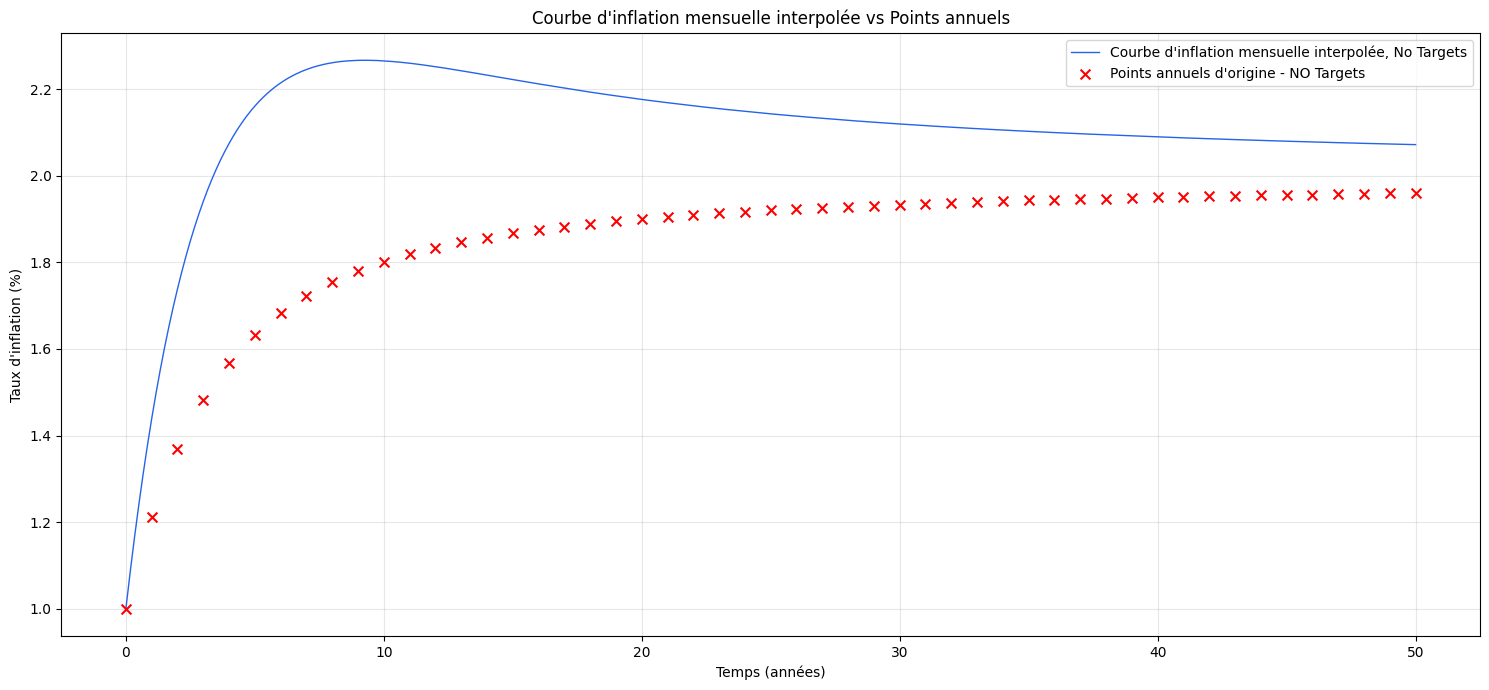

In [ ]:
plt.figure(figsize=(15, 7))
plt.plot(df_monthly_no_targets['Temps_Fraction_Annee'], df_monthly_no_targets['Inflation (%)'], label="Courbe d'inflation mensuelle interpolée, No Targets", color='#2563eb', linewidth=1)
plt.scatter(annual_years, annual_inflation_no_targets * 100, label="Points annuels d'origine - NO Targets", color='red', marker='x', s=50, zorder=5)

plt.title("Courbe d'inflation mensuelle interpolée vs Points annuels")
plt.xlabel("Temps (années)")
plt.ylabel("Taux d'inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
df_no_targets[["Année", "Inflation (%)"]].to_csv("courbe_inflation_nelson_siegel_NO_Targets.csv", index=False)
print("Fichier exporté : courbe_inflation_nelson_siegel_NO_Targets.csv")

Fichier exporté : courbe_inflation_nelson_siegel_NO_Targets.csv


# Expor Output

In [ ]:
# Définir les DataFrames à exporter dans un dictionnaire
excel_dfs = {
   "Annuel_Avec_Cibles": df,
   "Mensuel_Avec_Cibles": df_monthly,
   "Annuel_Sans_Cibles": df_no_targets,
   "Mensuel_Sans_Cibles": df_monthly_no_targets
}

# Nom du fichier Excel
output_file = "Courbes_Inflation_Completes.xlsx"

# Appel de la fonction pour exporter et télécharger
export_dfs_to_excel(excel_dfs, output_file)

Fichier créé : Courbes_Inflation_Completes.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#  Part2 - Construction de courbe de taux CTZ

=== Date: 31/12/2026 ===
  Taux court cible (3M) : 2.5700%
  Taux long cible (10Y Swap) : 3.4500% (Déduit de l'OAT 4.1100% - Spread 66bps)
  Paramètres Nelson-Siegel appliqués :
    b0 = 0.036458
    b1 = -0.011552
    b2 = 0.001753
    alpha = 1.999992
  Vérification Modèle vs Cibles :
    Modèle 3M  = 2.5700% (Écart : -0.00 bps)
    Modèle 10Y = 3.4500% (Écart : -0.00 bps)

=== Date: 31/12/2027 ===
  Taux court cible (3M) : 2.2000%
  Taux long cible (10Y Swap) : 3.3000% (Déduit de l'OAT 3.8000% - Spread 50bps)
  Paramètres Nelson-Siegel appliqués :
    b0 = 0.035478
    b1 = -0.014464
    b2 = 0.002058
    alpha = 1.999989
  Vérification Modèle vs Cibles :
    Modèle 3M  = 2.2000% (Écart : -0.00 bps)
    Modèle 10Y = 3.3000% (Écart : -0.00 bps)



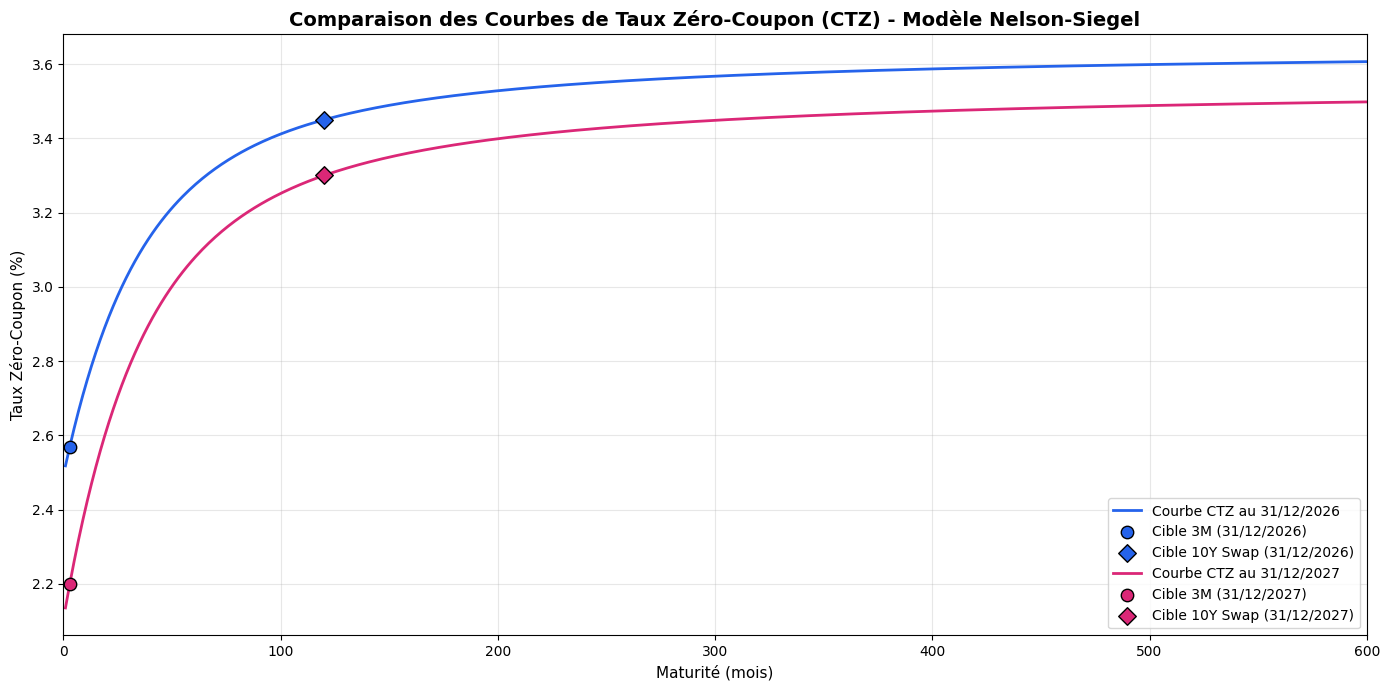

Aperçu des premières échéances mensuelles des courbes CTZ :


,Mois,Maturité_Année,Taux_CTZ_31_12_2026(%),Taux_CTZ_31_12_2027(%)
0,1,0.083333,2.5179,2.1353
1,2,0.166667,2.5444,2.1682
2,3,0.250000,2.5700,2.2000
3,4,0.333333,2.5948,2.2309
4,5,0.416667,2.6189,2.2608
5,6,0.500000,2.6423,2.2899
6,7,0.583333,2.6649,2.3180
7,8,0.666667,2.6869,2.3453
8,9,0.750000,2.7082,2.3718
9,10,0.833333,2.7289,2.3976


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- 1. MODÈLE NELSON-SIEGEL POUR LES TAUX ---
def nelson_siegel_rates(t, b0, b1, b2, alpha):
    """
    Calcule le taux Nelson-Siegel pour une maturité t (en années).
    """
    t = np.asarray(t, dtype=float)
    # Gérer la limite à t -> 0
    if t.ndim == 0:
        if t == 0:
            return b0 + b1
    x = t / alpha
    f1 = np.where(x == 0, 1.0, (1.0 - np.exp(-x)) / x)
    f2 = f1 - np.exp(-x)
    return b0 + b1 * f1 + b2 * f2

# --- 2. FONCTION DE CALIBRATION ---
def calibrate_ns_ctz(t_targets, r_targets, fixed_params=None, init_guess=(0.03, -0.01, 0.0, 2.0)):
    """
    Calibre les paramètres de Nelson-Siegel pour passer au plus près des points cibles.
    t_targets : liste/array des maturités en années (ex: [0.25, 10.0])
    r_targets : liste/array des taux cibles correspondants (ex: [0.0257, 0.0345])
    fixed_params : dict optionnel de paramètres forcés par l'utilisateur (ex: {'alpha': 2.0, 'b2': 0.01})
    """
    t_targets = np.array(t_targets)
    r_targets = np.array(r_targets)

    # Si des paramètres sont entièrement fixés par l'utilisateur, on ne les optimise pas
    if fixed_params is None:
        fixed_params = {}

    def objective(params_to_opt):
        # params_to_opt: [b0, b1, b2, alpha] (uniquement ceux non fixés)
        p_idx = 0

        b0 = fixed_params.get('b0', params_to_opt[p_idx] if 'b0' not in fixed_params else None)
        if 'b0' not in fixed_params: p_idx += 1

        b1 = fixed_params.get('b1', params_to_opt[p_idx] if 'b1' not in fixed_params else None)
        if 'b1' not in fixed_params: p_idx += 1

        b2 = fixed_params.get('b2', params_to_opt[p_idx] if 'b2' not in fixed_params else None)
        if 'b2' not in fixed_params: p_idx += 1

        alpha = fixed_params.get('alpha', params_to_opt[p_idx] if 'alpha' not in fixed_params else None)
        if 'alpha' not in fixed_params: p_idx += 1

        # Calcul des taux modélisés
        model_vals = nelson_siegel_rates(t_targets, b0, b1, b2, alpha)

        # Erreur quadratique
        return np.sum((model_vals - r_targets) ** 2)

    # Construire l'estimation initiale et les bornes pour les paramètres variables uniquement
    active_guess = []
    bounds = []

    param_names = ['b0', 'b1', 'b2', 'alpha']
    default_guesses = {'b0': init_guess[0], 'b1': init_guess[1], 'b2': init_guess[2], 'alpha': init_guess[3]}
    default_bounds = {'b0': (-0.1, 0.2), 'b1': (-0.2, 0.2), 'b2': (-0.3, 0.3), 'alpha': (0.5, 15.0)}

    for name in param_names:
        if name not in fixed_params:
            active_guess.append(default_guesses[name])
            bounds.append(default_bounds[name])

    if len(active_guess) == 0:
        # Tous les paramètres sont fixés manuellement
        return fixed_params

    res = minimize(objective, x0=active_guess, bounds=bounds, method='L-BFGS-B')

    # Reconstruire le dictionnaire complet des paramètres
    final_params = fixed_params.copy()
    p_idx = 0
    for name in param_names:
        if name not in final_params:
            final_params[name] = res.x[p_idx]
            p_idx += 1

    return final_params

# --- 3. CONFIGURATION DES INPUTS PAR SITUATION ---
situations = {
    "31/12/2026": {
        "euribor_3m": 0.0257,       # Input 1 : Taux Court 3M (2.57%)
        "oat_10y": 0.0411,          # Input 2 : Taux OAT 10 Ans (4.11%)
        "spread_france": 0.0066,    # Spread Rating France (66 bps)
    },
    "31/12/2027": {
        "euribor_3m": 0.0220,       # Exemple de taux court estimé pour 2027
        "oat_10y": 0.0380,          # Exemple d'OAT 10Y estimée
        "spread_france": 0.0050,    # Exemple spread France
    }
}

# Option de surcharge manuelle pour ajuster la forme/pente de la courbe
# Si vous voulez forcer un paramètre (par ex. fixer alpha=3.0 ou b2=0), renseignez-le ici.
# Laissez ce dictionnaire vide {} pour laisser l'optimiseur calibrer librement tous les paramètres.
manual_overrides = {}

# --- 4. CALCULS ET GÉNÉRATION DE LA COURBE ---
maturities_months = np.arange(1, 601)  # de 1 mois à 600 mois (50 ans)
maturities_years = maturities_months / 12.0

results = {}

for date, inputs in situations.items():
    # Calcul du taux long cible (Swap 10Y) = OAT 10Y - Spread
    swap_10y_target = inputs["oat_10y"] - inputs["spread_france"]

    t_targets = [0.25, 10.0]  # 3 Mois (0.25 an) et 10 Ans
    r_targets = [inputs["euribor_3m"], swap_10y_target]

    # Calibration
    calibrated_params = calibrate_ns_ctz(t_targets, r_targets, fixed_params=manual_overrides)

    # Génération de la courbe CTZ
    curve_rates = nelson_siegel_rates(maturities_years, **calibrated_params)

    results[date] = {
        "params": calibrated_params,
        "curve": curve_rates,
        "targets": {"3M": inputs["euribor_3m"], "10Y_Swap": swap_10y_target}
    }

    # Vérification et Affichage des résultats de calibration
    print(f"=== Date: {date} ===")
    print(f"  Taux court cible (3M) : {inputs['euribor_3m']:.4%}")
    print(f"  Taux long cible (10Y Swap) : {swap_10y_target:.4%} (Déduit de l'OAT {inputs['oat_10y']:.4%} - Spread {inputs['spread_france']*10000:.0f}bps)")
    print("  Paramètres Nelson-Siegel appliqués :")
    for k, v in calibrated_params.items():
        print(f"    {k} = {v:.6f}")

    # Vérification de l'écart aux cibles
    rate_3m_model = nelson_siegel_rates(0.25, **calibrated_params)
    rate_10y_model = nelson_siegel_rates(10.0, **calibrated_params)
    print(f"  Vérification Modèle vs Cibles :")
    print(f"    Modèle 3M  = {rate_3m_model:.4%} (Écart : {(rate_3m_model - inputs['euribor_3m'])*10000:.2f} bps)")
    print(f"    Modèle 10Y = {rate_10y_model:.4%} (Écart : {(rate_10y_model - swap_10y_target)*10000:.2f} bps)\n")

# --- 5. VISUALISATION DES DEUX COURBES CTZ ---
plt.figure(figsize=(14, 7))
colors = {'31/12/2026': '#2563eb', '31/12/2027': '#db2777'}

for date, res in results.items():
    plt.plot(maturities_months, res["curve"] * 100, label=f"Courbe CTZ au {date}", color=colors[date], linewidth=2)
    # Points cibles
    plt.scatter([3], [res["targets"]["3M"] * 100], color=colors[date], edgecolors='black', s=80, zorder=5, label=f"Cible 3M ({date})")
    plt.scatter([120], [res["targets"]["10Y_Swap"] * 100], color=colors[date], marker='D', edgecolors='black', s=80, zorder=5, label=f"Cible 10Y Swap ({date})")

plt.title("Comparaison des Courbes de Taux Zéro-Coupon (CTZ) - Modèle Nelson-Siegel", fontsize=14, fontweight='bold')
plt.xlabel("Maturité (mois)", fontsize=11)
plt.ylabel("Taux Zéro-Coupon (%)", fontsize=11)
plt.xlim(0, 600)
plt.grid(alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# --- 6. EXPORT DANS UN DATAFRAME COMPARATIF ---
df_ctz_comparison = pd.DataFrame({"Mois": maturities_months, "Maturité_Année": maturities_years})
for date, res in results.items():
    df_ctz_comparison[f"Taux_CTZ_{date.replace('/', '_')}(%)"] = (res["curve"] * 100).round(4)

print("Aperçu des premières échéances mensuelles des courbes CTZ :")
display(df_ctz_comparison.head(12))

# Dashboard

In [ ]:
%%writefile app.py
import streamlit as st
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from datetime import date
import io

st.set_page_config(page_title="Dashboard Calibration Nelson-Siegel", layout="wide")

st.title("📈 Dashboard Nelson-Siegel — Courbe de Taux Zéro-Coupon (CTZ)")
st.markdown("Ce dashboard permet de calibrer et personnaliser une courbe de taux Zéro-Coupon sur mesure en utilisant le modèle de Nelson-Siegel.")

# --- MODÈLE NELSON-SIEGEL ---
def nelson_siegel_rates(t, b0, b1, b2, alpha):
    t = np.asarray(t, dtype=float)
    if t.ndim == 0:
        if t == 0:
            return b0 + b1
    x = t / alpha
    f1 = np.where(x == 0, 1.0, (1.0 - np.exp(-x)) / x)
    f2 = f1 - np.exp(-x)
    return b0 + b1 * f1 + b2 * f2

# --- CALIBRATION ---
def calibrate_ns_ctz(t_targets, r_targets, fixed_params=None, init_guess=(0.03, -0.01, 0.0, 2.0)):
    t_targets = np.array(t_targets)
    r_targets = np.array(r_targets)
    if fixed_params is None:
        fixed_params = {}

    def objective(params_to_opt):
        p_idx = 0
        b0 = fixed_params.get('b0', params_to_opt[p_idx] if 'b0' not in fixed_params else None)
        if 'b0' not in fixed_params: p_idx += 1
        b1 = fixed_params.get('b1', params_to_opt[p_idx] if 'b1' not in fixed_params else None)
        if 'b1' not in fixed_params: p_idx += 1
        b2 = fixed_params.get('b2', params_to_opt[p_idx] if 'b2' not in fixed_params else None)
        if 'b2' not in fixed_params: p_idx += 1
        alpha = fixed_params.get('alpha', params_to_opt[p_idx] if 'alpha' not in fixed_params else None)
        if 'alpha' not in fixed_params: p_idx += 1

        model_vals = nelson_siegel_rates(t_targets, b0, b1, b2, alpha)
        return np.sum((model_vals - r_targets) ** 2)

    active_guess = []
    bounds = []
    param_names = ['b0', 'b1', 'b2', 'alpha']
    default_guesses = {'b0': init_guess[0], 'b1': init_guess[1], 'b2': init_guess[2], 'alpha': init_guess[3]}
    default_bounds = {'b0': (-0.1, 0.2), 'b1': (-0.2, 0.2), 'b2': (-0.3, 0.3), 'alpha': (0.5, 15.0)}

    for name in param_names:
        if name not in fixed_params:
            active_guess.append(default_guesses[name])
            bounds.append(default_bounds[name])

    if len(active_guess) == 0:
        return fixed_params

    res = minimize(objective, x0=active_guess, bounds=bounds, method='L-BFGS-B')

    final_params = fixed_params.copy()
    p_idx = 0
    for name in param_names:
        if name not in final_params:
            final_params[name] = res.x[p_idx]
            p_idx += 1
    return final_params

# --- SIDEBAR & INPUTS ---

st.sidebar.header("1️⃣ Inputs de Marché & Échéance")
euribor_3m = st.sidebar.number_input("Taux Court 3M (ex: 0.0257 pour 2.57%)", value=0.0257, format="%.4f")
oat_10y = st.sidebar.number_input("Taux OAT 10 Ans (ex: 0.0411 pour 4.11%)", value=0.0411, format="%.4f")
spread_france = st.sidebar.number_input("Spread Rating France (ex: 0.0066)", value=0.0066, format="%.4f")
max_months = st.sidebar.number_input("Maturité maximale de la courbe (mois)", value=600, min_value=12, max_value=1200, step=12)

swap_10y_target = oat_10y - spread_france
t_targets = [0.25, 10.0]
r_targets = [euribor_3m, swap_10y_target]

st.sidebar.header("2️⃣ Date de départ de la courbe")
selected_date = st.sidebar.date_input("Date d'évaluation", date(2026, 12, 31))

st.sidebar.header("3️⃣ Paramètres Nelson-Siegel")
mode_param = st.sidebar.radio("Mode des paramètres", ["Calibration Automatique", "Saisie Manuelle (Sliders)"])

if mode_param == "Calibration Automatique":
    # Calcul automatique
    params = calibrate_ns_ctz(t_targets, r_targets)
    b0 = st.sidebar.slider("Beta 0 (Niveau long terme)", -0.10, 0.20, float(params['b0']), step=0.0001, disabled=True)
    b1 = st.sidebar.slider("Beta 1 (Pente)", -0.20, 0.20, float(params['b1']), step=0.0001, disabled=True)
    b2 = st.sidebar.slider("Beta 2 (Courbure)", -0.30, 0.30, float(params['b2']), step=0.0001, disabled=True)
    alpha = st.sidebar.slider("Alpha (Vitesse de décroissance)", 0.5, 15.0, float(params['alpha']), step=0.1, disabled=True)
else:
    # Contrôle manuel par sliders
    b0 = st.sidebar.slider("Beta 0 (Niveau long terme)", -0.10, 0.20, 0.035, step=0.0001)
    b1 = st.sidebar.slider("Beta 1 (Pente)", -0.20, 0.20, -0.012, step=0.0001)
    b2 = st.sidebar.slider("Beta 2 (Courbure)", -0.30, 0.30, 0.002, step=0.0001)
    alpha = st.sidebar.slider("Alpha (Vitesse de décroissance)", 0.5, 15.0, 2.0, step=0.1)
    params = {'b0': b0, 'b1': b1, 'b2': b2, 'alpha': alpha}

# --- GENERATION DE LA COURBE ---
maturities_months = np.arange(1, max_months + 1)
maturities_years = maturities_months / 12.0
curve_rates = nelson_siegel_rates(maturities_years, **params)

# --- VISUALISATION (BLOC 4) ---
col1, col2 = st.columns([2, 1])

with col1:
    st.subheader("4️⃣ Graphique de la Courbe de Taux")
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.plot(maturities_months, curve_rates * 100, label=f"Courbe CTZ au {selected_date.strftime('%d/%m/%Y')}", color='#2563eb', linewidth=2.5)
    ax.scatter([3], [euribor_3m * 100], color='red', edgecolors='black', s=100, zorder=5, label=f"Cible 3M ({euribor_3m:.2%})")
    ax.scatter([120], [swap_10y_target * 100], color='green', marker='D', edgecolors='black', s=100, zorder=5, label=f"Cible 10Y Swap ({swap_10y_target:.2%})")

    ax.set_title("Courbe de Taux Zéro-Coupon (CTZ)", fontsize=12, fontweight='bold')
    ax.set_xlabel("Maturité (mois)")
    ax.set_ylabel("Taux (%)")
    ax.set_xlim(0, max_months)
    ax.grid(alpha=0.3)
    ax.legend()
    st.pyplot(fig)

with col2:
    st.subheader("Paramètres Appliqués")
    st.write(f"**Date choisie :** {selected_date.strftime('%d/%m/%Y')}")
    st.write(f"**Beta 0 (Niveau LT) :** {params['b0']:.6f}")
    st.write(f"**Beta 1 (Pente) :** {params['b1']:.6f}")
    st.write(f"**Beta 2 (Courbure) :** {params['b2']:.6f}")
    st.write(f"**Alpha :** {params['alpha']:.6f}")

    st.metric(label="Écart cible 3M", value=f"{(nelson_siegel_rates(0.25, **params) - euribor_3m)*10000:.2f} bps")
    st.metric(label="Écart cible 10Y", value=f"{(nelson_siegel_rates(10.0, **params) - swap_10y_target)*10000:.2f} bps")

# --- EXPORT EXCEL (BLOC 5) ---
st.subheader("5️⃣ Export et Téléchargement de la courbe")

df_export = pd.DataFrame({
    "Mois": maturities_months,
    "Maturité (Années)": maturities_years,
    "Taux Zéro-Coupon (Taux)": curve_rates,
    "Taux Zéro-Coupon (%)": (curve_rates * 100).round(4)
})

# Création du fichier Excel en mémoire
buffer = io.BytesIO()
with pd.ExcelWriter(buffer, engine='openpyxl') as writer:
    df_export.to_excel(writer, index=False, sheet_name=f"CTZ_{selected_date.strftime('%Y%m%d')}")

buffer.seek(0)

st.download_button(
    label="📥 Télécharger la Courbe au format Excel",
    data=buffer,
    file_name=f"Courbe_CTZ_{selected_date.strftime('%Y%m%d')}.xlsx",
    mime="application/vnd.openxmlformats-officedocument.spreadsheetml.sheet"
)
